# Models

In [1]:
# datascience
from datascience import *
import numpy as np

%matplotlib inline
import matplotlib.pyplot as plots
plots.style.use('fivethirtyeight')

In [2]:
# polars
import polars as pl
from IPython.display import display
import numpy as np

def _append(base, extra):
    """Append a value or a Series onto a Series."""
    extra_s = extra if isinstance(extra, pl.Series) else pl.Series([extra])
    if base.len() == 0:
        return extra_s
    if base.dtype != extra_s.dtype:
        try:
            extra_s = extra_s.cast(base.dtype, strict=False)
        except Exception:
            base = base.cast(extra_s.dtype, strict=False)
    return pl.concat([base, extra_s])

def sample_proportions_pl(sample_size, proportions):
    """Draw `sample_size` items from `proportions` and return each category's share.

    A category that is not drawn stays 0. Polars `sample` has no weights, so the
    draw uses `np.random.choice`.
    """
    proportions = list(proportions)
    categories = list(range(len(proportions)))
    drawn = np.random.choice(categories, size=sample_size, p=proportions)
    counts = pl.Series("drawn", drawn).value_counts()
    count_dict = dict(zip(counts["drawn"].to_list(), counts["count"].to_list()))
    return [count_dict.get(cat, 0) / sample_size for cat in categories]


## Empirical Distributions of a Statistic

In [3]:
# datascience
united = Table.read_table('united.csv')
united = united.with_column('Row', np.arange(united.num_rows)).move_to_start('Row')

In [4]:
# polars
united_pl = pl.read_csv('united.csv', eol_char='\r')
united_pl = (lambda _df, _c='Row': _df.select([_c] + [c for c in _df.columns if c != _c]))(united_pl.with_columns(pl.Series('Row', pl.int_range(united_pl.height, eager=True))))

In [5]:
# datascience
# (Population) Parameter
np.median(united.column('Delay'))

2.0

In [6]:
# polars
# (Population) Parameter
(united_pl.get_column('Delay')).median()

2.0

In [7]:
# datascience
def sample_median(size):
    return np.median(united.sample(size).column('Delay'))

In [8]:
# polars
def sample_median_pl(size):
    return ((united_pl).sample(n=size, with_replacement=True, shuffle=True).get_column('Delay')).median()

In [9]:
# datascience
# (Sample) Statistic
sample_median(10)

2.0

In [10]:
# polars
# (Sample) Statistic
sample_median_pl(10)

-2.5

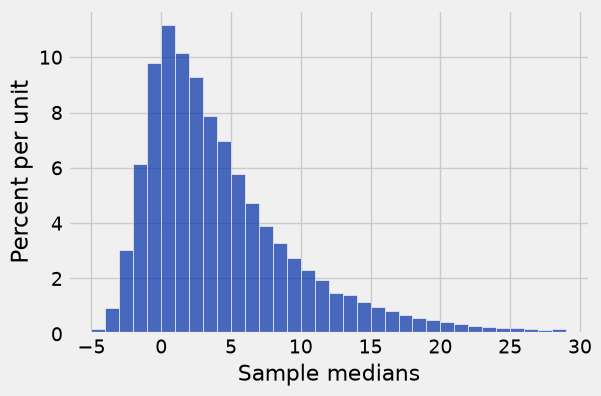

In [11]:
# datascience
sample_medians = make_array()

for i in np.arange(100000):
    new_median = sample_median(10)
    sample_medians = np.append(sample_medians, new_median)

Table().with_column('Sample medians', sample_medians).hist(bins=np.arange(-5, 30))

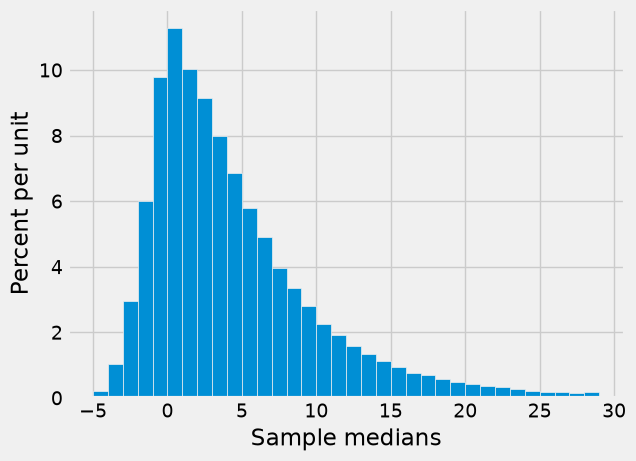

In [12]:
# polars
# matplotlib
sample_medians_pl = []

for i in pl.int_range(100000, eager=True):
    new_median = sample_median_pl(10)
    sample_medians_pl.append(new_median)

sample_medians_pl = pl.Series("values", sample_medians_pl)
_df = pl.DataFrame({'Sample medians': sample_medians_pl})
_cols = [c for c in _df.columns if _df[c].dtype.is_numeric()]
if len(_cols) == 1:
    plots.hist(_df.get_column(_cols[0]).to_numpy(), density=True, bins=(lambda _b: _b.to_numpy() if hasattr(_b, 'to_numpy') else _b)(pl.int_range(-5, 30, eager=True)))
    plots.xlabel(_cols[0])
else:
    for _col in _cols:
        plots.hist(_df.get_column(_col).to_numpy(), density=True, label=_col, bins=(lambda _b: _b.to_numpy() if hasattr(_b, 'to_numpy') else _b)(pl.int_range(-5, 30, eager=True)))
    plots.legend()
plots.ylabel("Percent per unit")
plots.gca().yaxis.set_major_formatter(lambda x, pos: "{:g}".format(100 * x))

**DISCUSS**:

1. Is the sample median a parameter or a statistic? Why?
1. What distribution is being shown in this chart? What is a sample median?
1. How does the law of averages apply here?
1. What can we learn from this chart?

In [13]:
# datascience
# (Sample) Statistic
sample_median(100)

2.0

In [14]:
# polars
# (Sample) Statistic
sample_median_pl(100)

4.0

In [15]:
# datascience
sample_medians_10 = make_array()
sample_medians_100 = make_array()
sample_medians_1000 = make_array()

num_simulations = 5000

for i in np.arange(num_simulations):
    new_median_10 = sample_median(10)
    sample_medians_10 = np.append(sample_medians_10, new_median_10)
    new_median_100 = sample_median(100)
    sample_medians_100 = np.append(sample_medians_100, new_median_100)
    new_median_1000 = sample_median(1000)
    sample_medians_1000 = np.append(sample_medians_1000, new_median_1000)

In [16]:
# polars
sample_medians_10_pl = []
sample_medians_100_pl = []
sample_medians_1000_pl = []

num_simulations_pl = 5000

for i in pl.int_range(num_simulations_pl, eager=True):
    new_median_10 = sample_median_pl(10)
    sample_medians_10_pl.append(new_median_10)
    new_median_100 = sample_median_pl(100)
    sample_medians_100_pl.append(new_median_100)
    new_median_1000 = sample_median_pl(1000)
    sample_medians_1000_pl.append(new_median_1000)
sample_medians_10_pl = pl.Series("values", sample_medians_10_pl)
sample_medians_100_pl = pl.Series("values", sample_medians_100_pl)
sample_medians_1000_pl = pl.Series("values", sample_medians_1000_pl)

In [17]:
# datascience
sample_medians = Table().with_columns('Size 10', sample_medians_10, 
                                      'Size 100', sample_medians_100,
                                      'Size 1000', sample_medians_1000)

In [18]:
# polars
sample_medians_pl = pl.DataFrame({'Size 10': sample_medians_10_pl, 'Size 100': sample_medians_100_pl, 'Size 1000': sample_medians_1000_pl})

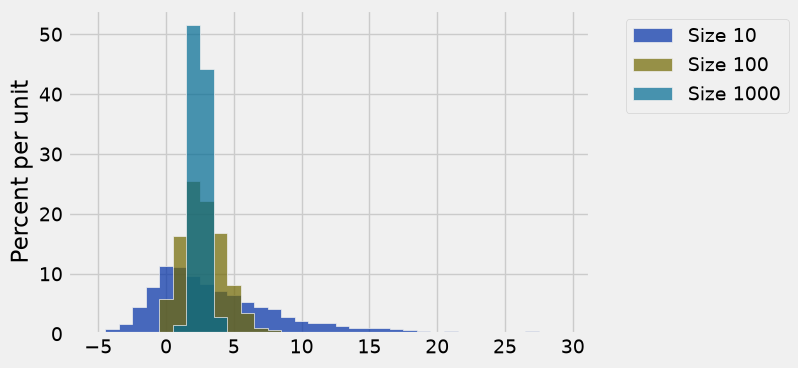

In [19]:
# datascience
sample_medians.hist(bins = np.arange(-5.5, 30.5))

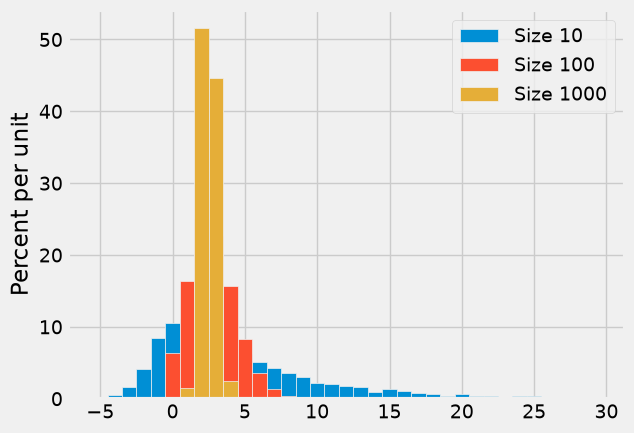

In [20]:
# polars
# matplotlib
_df = sample_medians_pl
_cols = [c for c in _df.columns if _df[c].dtype.is_numeric()]
if len(_cols) == 1:
    plots.hist(_df.get_column(_cols[0]).to_numpy(), density=True, bins=(lambda _b: _b.to_numpy() if hasattr(_b, 'to_numpy') else _b)(pl.linear_space(-5.5, 29.5, 36, closed="both", eager=True)))
    plots.xlabel(_cols[0])
else:
    for _col in _cols:
        plots.hist(_df.get_column(_col).to_numpy(), density=True, label=_col, bins=(lambda _b: _b.to_numpy() if hasattr(_b, 'to_numpy') else _b)(pl.linear_space(-5.5, 29.5, 36, closed="both", eager=True)))
    plots.legend()
plots.ylabel("Percent per unit")
plots.gca().yaxis.set_major_formatter(lambda x, pos: "{:g}".format(100 * x))

**DISCUSS**:

1. What are the three distributions shown in this chart? Are they statistics or parameters?
1. What can we learn from this chart?
1. Suppose we only had one sample of 100 flights. Can you use this chart to determine the chance that the sample median is at least five?

## Swain vs. Alabama ##

In [21]:
# datascience
# Example: roll a six-sided die ten times
fair_die_proportions = make_array(1/6, 1/6, 1/6, 1/6, 1/6, 1/6)

# return the empirical distribution of categories per sample
sample_proportions(10, fair_die_proportions)

array([ 0.2,  0. ,  0.1,  0.1,  0.1,  0.5])

In [22]:
#polars_with_ss_imported
from datascience import sample_proportions
# POLARS_CHANGE: sample_proportions returns an array; store it as a Series
# Example: roll a six-sided die ten times
fair_die_proportions_pl = pl.Series("values", [1/6, 1/6, 1/6, 1/6, 1/6, 1/6])

# return the empirical distribution of categories per sample
pl.Series("draw", sample_proportions(10, list(fair_die_proportions_pl)))

draw
f64
0.2
0.2
0.3
0.0
0.2
0.1


In [23]:
#polars-with-helper
# POLARS_CHANGE: sample_proportions returns an array; store it as a Series
# Example: roll a six-sided die ten times
fair_die_proportions_pl = pl.Series("values", [1/6, 1/6, 1/6, 1/6, 1/6, 1/6])

# return the empirical distribution of categories per sample
pl.Series("draw", sample_proportions_pl(10, list(fair_die_proportions_pl)))

draw
f64
0.0
0.3
0.3
0.0
0.4
0.0


In [24]:
# datascience
# MODEL of fairness: probability distribution
population_proportions = make_array(.26, .74)
population_proportions

array([ 0.26,  0.74])

In [25]:
# polars
# MODEL of fairness: probability distribution
population_proportions_pl = pl.Series("values", [.26, .74])
population_proportions_pl

values
f64
0.26
0.74


In [26]:
# datascience
# empirical distribution
sample_proportions(100, population_proportions)

array([ 0.24,  0.76])

In [27]:
#polars_with_ss_imported
from datascience import sample_proportions
# POLARS_CHANGE: sample_proportions returns an array; store it as a Series
# empirical distribution
pl.Series("draw", sample_proportions(100, list(population_proportions_pl)))

draw
f64
0.26
0.74


In [28]:
#polars-with-helper
# POLARS_CHANGE: sample_proportions returns an array; store it as a Series
# empirical distribution
pl.Series("draw", sample_proportions_pl(100, list(population_proportions_pl)))

draw
f64
0.3
0.7


In [29]:
# datascience
# statistic: the proportion of black jurors in a 100-person sample
sample_proportions(100, population_proportions).item(0)

0.28

In [30]:
#polars_with_ss_imported
from datascience import sample_proportions
# POLARS_CHANGE: sample_proportions returns an array; store it as a Series
# statistic: the proportion of black jurors in a 100-person sample
pl.Series("draw", sample_proportions(100, list(population_proportions_pl))).item(0)

0.22

In [31]:
#polars-with-helper
# POLARS_CHANGE: sample_proportions returns an array; store it as a Series
# statistic: the proportion of black jurors in a 100-person sample
pl.Series("draw", sample_proportions_pl(100, list(population_proportions_pl))).item(0)

0.2

In [32]:
# datascience
# 1. define function that simulates one outcome of the experiment
def panel_proportion():
    return sample_proportions(100, population_proportions).item(0)

In [33]:
#polars_with_ss_imported
from datascience import sample_proportions
# POLARS_CHANGE: sample_proportions returns an array; store it as a Series
# 1. define function that simulates one outcome of the experiment
def panel_proportion_pl():
    return pl.Series("draw", sample_proportions(100, list(population_proportions_pl))).item(0)

In [34]:
#polars-with-helper
# POLARS_CHANGE: sample_proportions returns an array; store it as a Series
# 1. define function that simulates one outcome of the experiment
def panel_proportion_pl():
    return pl.Series("draw", sample_proportions_pl(100, list(population_proportions_pl))).item(0)

In [35]:
# datascience
panel_proportion()

0.24

In [36]:
# polars
panel_proportion_pl()

0.24

In [37]:
# datascience
# 2. record outcomes of repeating the simulated experiment many times
panels = make_array()

for i in np.arange(10000):
    new_panel = panel_proportion() * 100
    panels = np.append(panels, new_panel)

In [38]:
# polars
# 2. record outcomes of repeating the simulated experiment many times
panels_pl = []

for i in pl.int_range(10000, eager=True):
    new_panel = panel_proportion_pl() * 100
    panels_pl.append(new_panel)
panels_pl = pl.Series("values", panels_pl)

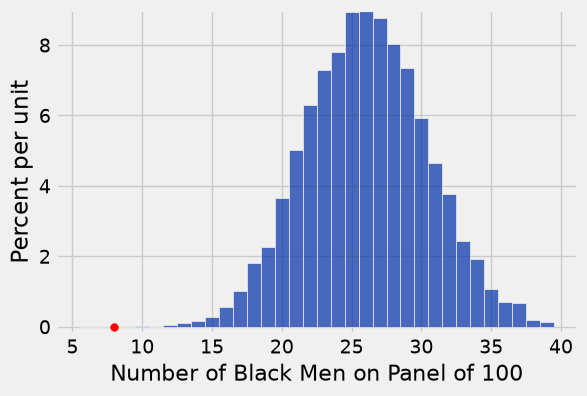

In [39]:
# datascience
Table().with_column(
    'Number of Black Men on Panel of 100', panels
).hist(bins=np.arange(5.5,40.))

# Plotting details; ignore this code
plots.ylim(-0.002, 0.09)
plots.scatter(8, 0, color='red', s=30);

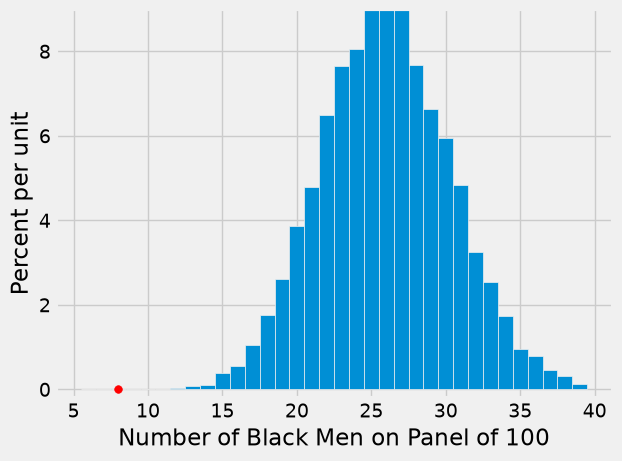

In [40]:
# polars
# matplotlib
_df = pl.DataFrame({'Number of Black Men on Panel of 100': panels_pl})
_cols = [c for c in _df.columns if _df[c].dtype.is_numeric()]
if len(_cols) == 1:
    plots.hist(_df.get_column(_cols[0]).to_numpy(), density=True, bins=(lambda _b: _b.to_numpy() if hasattr(_b, 'to_numpy') else _b)(pl.linear_space(5.5, 39.5, 35, closed="both", eager=True)))
    plots.xlabel(_cols[0])
else:
    for _col in _cols:
        plots.hist(_df.get_column(_col).to_numpy(), density=True, label=_col, bins=(lambda _b: _b.to_numpy() if hasattr(_b, 'to_numpy') else _b)(pl.linear_space(5.5, 39.5, 35, closed="both", eager=True)))
    plots.legend()
plots.ylabel("Percent per unit")
plots.gca().yaxis.set_major_formatter(lambda x, pos: "{:g}".format(100 * x))

# Plotting details; ignore this code
plots.ylim(-0.002, 0.09)
plots.scatter(8, 0, color='red', s=30);

In [41]:
# datascience
simulated_panels = Table().with_column(
    'Number of Black Men on Panel of 100', panels
)
simulated_panels.where('Number of Black Men on Panel of 100', are.below_or_equal_to(15)).num_rows/simulated_panels.num_rows

0.0062

In [42]:
# polars
simulated_panels_pl = pl.DataFrame({'Number of Black Men on Panel of 100': panels_pl})
simulated_panels_pl.filter(pl.col('Number of Black Men on Panel of 100') <= 15).height/simulated_panels_pl.height

0.0062

## Mendel and Pea Flowers ##

In [43]:
## Mendel had 929 plants, of which 709 had purple flowers
observed_purples = 709 / 929 # ACTUALLY GREW FLOWERS: OBSERVATION
observed_purples

0.7631862217438106

In [44]:
# datascience
# MODEL: probability distribution
predicted_proportions = make_array(.75, .25)
sample_proportions(929, predicted_proportions)

array([ 0.7416577,  0.2583423])

In [45]:
#polars_with_ss_imported
from datascience import sample_proportions
# POLARS_CHANGE: sample_proportions returns an array; store it as a Series
# MODEL: probability distribution
predicted_proportions_pl = pl.Series("values", [.75, .25])
pl.Series("draw", sample_proportions(929, list(predicted_proportions_pl)))

draw
f64
0.753498
0.246502


In [46]:
#polars-with-helper
# POLARS_CHANGE: sample_proportions returns an array; store it as a Series
# MODEL: probability distribution
predicted_proportions_pl = pl.Series("values", [.75, .25])
pl.Series("draw", sample_proportions_pl(929, list(predicted_proportions_pl)))

draw
f64
0.745963
0.254037


In [47]:
# datascience
def purple_flowers():
    return sample_proportions(929, predicted_proportions).item(0) * 100

In [48]:
#polars_with_ss_imported
from datascience import sample_proportions
# POLARS_CHANGE: sample_proportions returns an array; store it as a Series
def purple_flowers_pl():
    return pl.Series("draw", sample_proportions(929, list(predicted_proportions_pl))).item(0) * 100

In [49]:
#polars-with-helper
# POLARS_CHANGE: sample_proportions returns an array; store it as a Series
def purple_flowers_pl():
    return pl.Series("draw", sample_proportions_pl(929, list(predicted_proportions_pl))).item(0) * 100

In [50]:
# datascience
purple_flowers() # remove: SIMULATION UNDER THE ASSUMPTION OF 75/25

75.67276641550053

In [51]:
# polars
purple_flowers_pl() # remove: SIMULATION UNDER THE ASSUMPTION OF 75/25

71.79763186221744

In [52]:
# datascience
purples = make_array()

for i in np.arange(10000):
    new_purple = purple_flowers()
    purples = np.append(purples, new_purple)

In [53]:
# polars
purples_pl = []

for i in pl.int_range(10000, eager=True):
    new_purple = purple_flowers_pl()
    purples_pl.append(new_purple)
purples_pl = pl.Series("values", purples_pl)

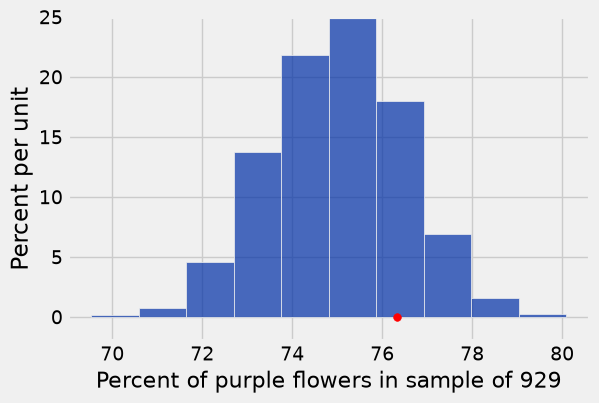

In [54]:
# datascience
Table().with_column('Percent of purple flowers in sample of 929', purples).hist()

# Plotting details; ignore this code
plots.ylim(-0.02, 0.25)
plots.scatter(observed_purples * 100, 0, color='red', s=30);

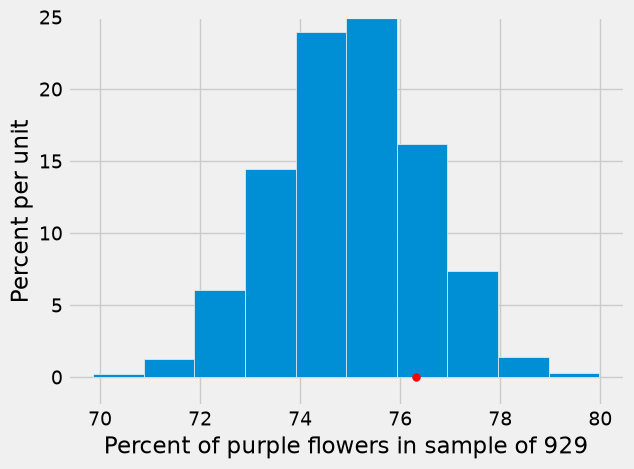

In [55]:
# polars
# matplotlib
_df = pl.DataFrame({'Percent of purple flowers in sample of 929': purples_pl})
_cols = [c for c in _df.columns if _df[c].dtype.is_numeric()]
if len(_cols) == 1:
    plots.hist(_df.get_column(_cols[0]).to_numpy(), density=True)
    plots.xlabel(_cols[0])
else:
    for _col in _cols:
        plots.hist(_df.get_column(_col).to_numpy(), density=True, label=_col)
    plots.legend()
plots.ylabel("Percent per unit")
plots.gca().yaxis.set_major_formatter(lambda x, pos: "{:g}".format(100 * x))

# Plotting details; ignore this code
plots.ylim(-0.02, 0.25)
plots.scatter(observed_purples * 100, 0, color='red', s=30);

In [56]:
observed_statistic = abs(observed_purples * 100 - 75)
observed_statistic

1.318622174381062

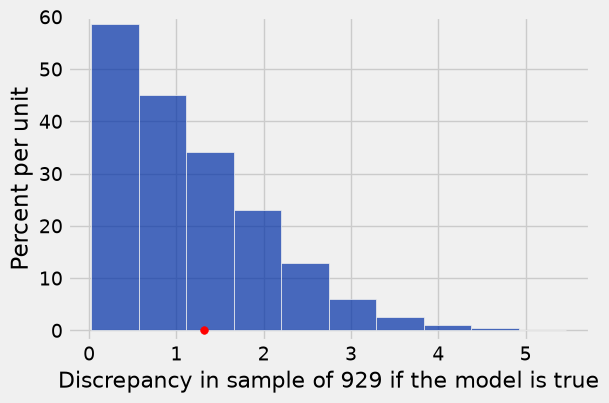

In [57]:
# datascience
simulated_statistics = abs(purples- 75)

Table().with_column('Discrepancy in sample of 929 if the model is true', simulated_statistics).hist()

# Plotting details; ignore this code
plots.ylim(-0.02, 0.6)
plots.scatter(observed_statistic, 0, color='red', s=30);

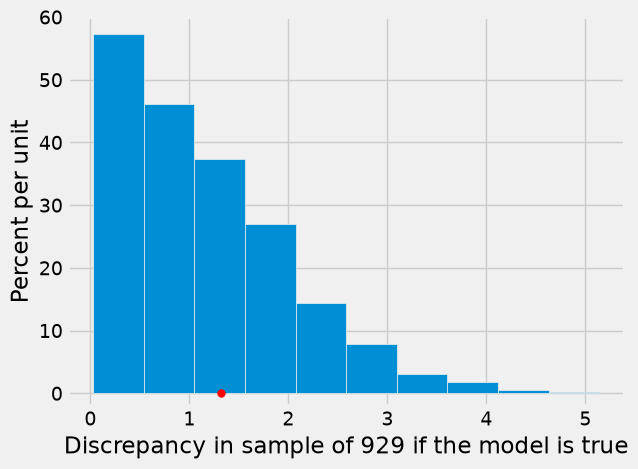

In [58]:
# polars
# matplotlib
simulated_statistics_pl = abs(purples_pl- 75)

_df = pl.DataFrame({'Discrepancy in sample of 929 if the model is true': simulated_statistics_pl})
_cols = [c for c in _df.columns if _df[c].dtype.is_numeric()]
if len(_cols) == 1:
    plots.hist(_df.get_column(_cols[0]).to_numpy(), density=True)
    plots.xlabel(_cols[0])
else:
    for _col in _cols:
        plots.hist(_df.get_column(_col).to_numpy(), density=True, label=_col)
    plots.legend()
plots.ylabel("Percent per unit")
plots.gca().yaxis.set_major_formatter(lambda x, pos: "{:g}".format(100 * x))

# Plotting details; ignore this code
plots.ylim(-0.02, 0.6)
plots.scatter(observed_statistic, 0, color='red', s=30);